# FineVideo EDA — the 50 Parquet files for the Alethia take-home

Goal: understand what `run.py` will have to chew through, so speed/correctness decisions are grounded in data.

Questions this notebook answers:
1. What is in the Parquet files (schema, rows per file, bytes)?
2. **What resolutions are the videos**, and what does that mean for YOLO's 640 letterbox input?
3. Durations, frame rates, total frames, total output seconds (= output lines).
4. Codecs, GOP / keyframe structure, B-frames — what decoding will cost.
5. Rotation tags, variable frame rate, timestamp offsets, damaged videos — the edge cases the brief warns about.
6. How many frames fall into each one-second bucket (matters for per-second sampling).
7. Content categories and what the frames actually look like.
8. How fast can the CPU decode these videos?

The expensive full scan (demux of every packet of every video, no pixel decoding) is cached to `eda_cache/video_meta.parquet`; delete that file to rescan.

In [1]:
import io, os, time, math, json, random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import av
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110

DATA_DIR = Path(r"F:\alethia\code_files\finevideo\data")
CACHE_DIR = Path("eda_cache")
CACHE_DIR.mkdir(exist_ok=True)
files = sorted(DATA_DIR.glob("*.parquet"))
print(f"{len(files)} parquet files, PyAV {av.__version__}, pyarrow {pa.__version__}")

50 parquet files, PyAV 17.1.0, pyarrow 25.0.1


## 1. The Parquet files

In [2]:
rows = []
for f in files:
    md = pq.ParquetFile(f).metadata
    rows.append({"file": f.name, "size_mb": f.stat().st_size / 2**20,
                 "num_rows": md.num_rows, "row_groups": md.num_row_groups})
files_df = pd.DataFrame(rows)
print(f"Total size: {files_df.size_mb.sum()/1024:.2f} GB | total videos (rows): {files_df.num_rows.sum()}")
print(f"Row groups per file: {files_df.row_groups.unique()}")
files_df.describe().round(1)

Total size: 23.12 GB | total videos (rows): 1650
Row groups per file: [1]


,size_mb,num_rows,row_groups
count,50.0,50.0,50.0
mean,473.5,33.0,1.0
std,59.0,0.0,0.0
min,329.9,33.0,1.0
25%,435.9,33.0,1.0
50%,470.8,33.0,1.0
75%,523.2,33.0,1.0
max,615.8,33.0,1.0


In [3]:
schema = pq.ParquetFile(files[0]).schema_arrow
print("Top-level columns:", schema.names)
print("json struct fields:", [f.name for f in schema.field("json").type])

Top-level columns: ['mp4', 'json']
json struct fields: ['content_fine_category', 'content_metadata', 'content_parent_category', 'duration_seconds', 'original_json_filename', 'original_video_filename', 'resolution', 'text_to_speech', 'text_to_speech_word_count', 'timecoded_text_to_speech', 'youtube_age_limit', 'youtube_categories', 'youtube_channel', 'youtube_channel_follower_count', 'youtube_comment_count', 'youtube_description', 'youtube_like_count', 'youtube_tags', 'youtube_title', 'youtube_upload_date', 'youtube_view_count']


Each row = one video. `mp4` is the raw file bytes; `json` is a big nested struct of annotations.
The brief says we don't need `json` — but it has a declared `resolution`, `duration_seconds` and `fps`,
which are handy to cross-check against what the actual video streams say.

## 2. The `json` metadata (declared values)

In [4]:
def load_json_meta(path):
    t = pq.read_table(path, columns=["json"])
    s = t.column("json").combine_chunks()
    cm = s.field("content_metadata")
    return pd.DataFrame({
        "file": path.name,
        "row": np.arange(len(s)),
        "json_resolution": s.field("resolution").to_pylist(),
        "json_duration_s": s.field("duration_seconds").to_pylist(),
        "json_fps": cm.field("fps").to_pylist(),
        "parent_category": s.field("content_parent_category").to_pylist(),
        "fine_category": s.field("content_fine_category").to_pylist(),
        "title": s.field("youtube_title").to_pylist(),
    })

json_df = pd.concat([load_json_meta(f) for f in files], ignore_index=True)
json_df["video"] = json_df.file + ":" + json_df.row.astype(str)
print(len(json_df), "videos")
json_df.head()

1650 videos


,file,row,json_resolution,json_duration_s,json_fps,parent_category,fine_category,title,video
0,train-00000-of-01357.parquet,0,640x360,208,23.976025,Education,Engineering Projects,Training Heavy Equipment Operators,train-00000-of-01357.parquet:0
1,train-00000-of-01357.parquet,1,640x360,604,29.970000,Entertainment,Game Reviews,Forspoken after 100% Completion + Star Ocean T...,train-00000-of-01357.parquet:1
2,train-00000-of-01357.parquet,2,640x360,268,25.000000,Sports,Career Highlights,Life at the Academy - Queensland Police Service,train-00000-of-01357.parquet:2
3,train-00000-of-01357.parquet,3,626x360,410,29.779000,Lifestyle,Recipe Videos,"Vendakka Moru Curry, Ladysfinger Yoghurt Curry...",train-00000-of-01357.parquet:3
4,train-00000-of-01357.parquet,4,270x480,48,30.000000,Lifestyle,Fashion Hauls,The secrets behind the luxurious Goyard Mini A...,train-00000-of-01357.parquet:4


In [5]:
json_df.json_resolution.value_counts().head(20)

json_resolution
640x360    1284
360x640     141
480x360      49
270x480      31
202x360      28
320x240       9
360x360       6
640x352       6
540x360       6
576x360       5
204x360       4
640x356       4
636x360       3
640x272       3
490x360       3
640x358       3
480x270       3
640x270       3
638x360       2
640x320       2
Name: count, dtype: int64

## 3. Full container scan of every video (actual stream values)

For every video: open the mp4 from memory with PyAV, read stream info, **demux every video packet** (cheap — no pixel decoding)
to get exact frame timestamps, keyframes and frame count, then decode only the first frame to read its rotation.
Any failure is recorded instead of crashing — exactly what `run.py` must do too.

In [6]:
def probe_video(mp4_bytes):
    rec = {"mp4_mb": len(mp4_bytes) / 2**20 if mp4_bytes is not None else 0.0, "error": None}
    if not mp4_bytes:
        rec["error"] = "empty mp4 bytes"
        return rec
    try:
        with av.open(io.BytesIO(mp4_bytes)) as c:
            rec["container"] = c.format.name
            rec["container_duration_s"] = c.duration / 1e6 if c.duration else np.nan
            rec["n_video_streams"] = len(c.streams.video)
            rec["n_audio_streams"] = len(c.streams.audio)
            if not c.streams.video:
                rec["error"] = "no video stream"
                return rec
            v = c.streams.video[0]
            cc = v.codec_context
            tb = v.time_base
            rec.update(
                codec=cc.name, profile=cc.profile, pix_fmt=cc.pix_fmt,
                width=cc.width, height=cc.height,
                avg_fps=float(v.average_rate) if v.average_rate else np.nan,
                base_fps=float(v.base_rate) if v.base_rate else np.nan,
                declared_frames=v.frames,
                bit_rate_kbps=(cc.bit_rate or 0) / 1000,
                has_b_frames=getattr(cc, "has_b_frames", None),
            )
            pts, keys = [], []
            for p in c.demux(v):
                if p.size == 0 or p.pts is None:      # flush / empty packets
                    continue
                pts.append(p.pts)
                keys.append(p.is_keyframe)
        if not pts:
            rec["error"] = "no video packets"
            return rec
        order = np.argsort(pts)
        t = np.asarray(pts, dtype=np.float64)[order] * float(tb)
        k = np.asarray(keys)[order]
        t0 = t[0]
        rel = t - t0
        d = np.diff(t)
        rec.update(
            n_frames=len(t),
            first_pts_s=t0,
            last_rel_s=rel[-1],
            n_seconds=int(math.floor(rel[-1])) + 1,          # output lines for this video
            dt_median_ms=np.median(d) * 1000 if len(d) else np.nan,
            dt_min_ms=d.min() * 1000 if len(d) else np.nan,
            dt_max_ms=d.max() * 1000 if len(d) else np.nan,
            dt_cv=(d.std() / d.mean()) if len(d) > 1 and d.mean() > 0 else 0.0,
            dup_pts=int((d == 0).sum()),
            n_keyframes=int(k.sum()),
        )
        kidx = np.flatnonzero(k)
        rec["gop_median_frames"] = float(np.median(np.diff(kidx))) if len(kidx) > 1 else float(len(t))
        # frames per 1-second bucket, excluding the (partial) last second
        counts = np.bincount(np.floor(rel).astype(int))
        full = counts[:-1] if len(counts) > 1 else counts
        rec["fpsbucket_min"] = int(full.min())
        rec["fpsbucket_max"] = int(full.max())
        rec["empty_buckets"] = int((counts == 0).sum())
        # rotation: decode just the first frame
        with av.open(io.BytesIO(mp4_bytes)) as c2:
            fr = next(c2.decode(video=0))
            rec["rotation"] = int(getattr(fr, "rotation", 0) or 0)
            rec["first_decoded_pts_s"] = fr.time
            rec["frame_w"], rec["frame_h"] = fr.width, fr.height
    except Exception as e:  # damaged video etc.
        rec["error"] = f"{type(e).__name__}: {e}"[:200]
    return rec


def scan_file(path):
    t = pq.read_table(path, columns=["mp4"])
    col = t.column("mp4")
    out = []
    for i in range(t.num_rows):
        b = col[i].as_py()
        r = probe_video(b)
        r["file"], r["row"] = path.name, i
        out.append(r)
    return out

In [7]:
META_CACHE = CACHE_DIR / "video_meta.parquet"
if META_CACHE.exists():
    meta = pd.read_parquet(META_CACHE)
    print("loaded cache", META_CACHE)
else:
    t_start = time.time()
    recs = []
    with ThreadPoolExecutor(max_workers=4) as ex:
        futs = {ex.submit(scan_file, f): f for f in files}
        for n, fut in enumerate(as_completed(futs), 1):
            recs.extend(fut.result())
            if n % 5 == 0:
                print(f"{n}/{len(files)} files scanned, {time.time()-t_start:.0f}s")
    meta = pd.DataFrame(recs)
    meta.to_parquet(META_CACHE)
    print(f"scan took {time.time()-t_start:.0f}s")

meta["video"] = meta.file + ":" + meta.row.astype(str)
df = meta.merge(json_df.drop(columns=["file", "row"]), on="video", how="left")
print(df.shape)
df.head()

5/50 files scanned, 73s
10/50 files scanned, 142s
15/50 files scanned, 227s
20/50 files scanned, 316s
25/50 files scanned, 450s
30/50 files scanned, 535s
35/50 files scanned, 638s
40/50 files scanned, 708s
45/50 files scanned, 839s
50/50 files scanned, 867s
scan took 867s
(1650, 43)


,mp4_mb,error,container,container_duration_s,n_video_streams,n_audio_streams,codec,profile,pix_fmt,width,height,avg_fps,base_fps,declared_frames,bit_rate_kbps,has_b_frames,n_frames,first_pts_s,last_rel_s,n_seconds,dt_median_ms,dt_min_ms,dt_max_ms,dt_cv,dup_pts,n_keyframes,gop_median_frames,fpsbucket_min,fpsbucket_max,empty_buckets,rotation,first_decoded_pts_s,frame_w,frame_h,file,row,video,json_resolution,json_duration_s,json_fps,parent_category,fine_category,title
0,2.687284,None,"mov,mp4,m4a,3gp,3g2,mj2",49.946122,1,1,h264,Main,yuv420p,640,360,23.976024,23.976024,1197,320.204,True,1197,0.0,49.883167,50,41.708333,41.708333,41.708333,4.236168e-14,0,30,36.0,23,24,0,0,0.0,640,360,train-00003-of-01357.parquet,0,train-00003-of-01357.parquet:0,640x360,50,23.976024,Lifestyle,Parenting Tips,An Introduction to Imitation – Teaching your c...
1,12.608011,None,"mov,mp4,m4a,3gp,3g2,mj2",221.657687,1,1,h264,Main,yuv420p,640,360,29.970030,29.970030,6643,345.980,True,6643,0.0,221.621400,222,33.366667,33.366667,33.366667,1.089063e-13,0,42,160.0,29,30,0,0,0.0,640,360,train-00003-of-01357.parquet,1,train-00003-of-01357.parquet:1,640x360,222,29.970030,News & Politics,Political Interviews,Vivek Ramaswamy joins NewsNation
2,9.035534,None,"mov,mp4,m4a,3gp,3g2,mj2",141.200544,1,1,h264,Main,yuv420p,480,360,30.000000,30.000000,4236,405.078,True,4236,0.0,141.166667,142,33.333333,33.333333,33.333333,1.266455e-13,0,27,160.0,30,30,0,0,0.0,480,360,train-00003-of-01357.parquet,2,train-00003-of-01357.parquet:2,480x360,141,30.000000,Hobbies & Interests,Memorabilia,david robinson and hakeem olajuwon game used card
3,3.448260,None,"mov,mp4,m4a,3gp,3g2,mj2",57.910567,1,1,h264,Main,yuv420p,360,640,30.000000,30.000000,1737,367.169,True,1737,0.0,57.866667,58,33.333333,33.333333,33.333333,6.918100e-14,0,19,83.5,30,30,0,0,0.0,360,640,train-00003-of-01357.parquet,3,train-00003-of-01357.parquet:3,360x640,58,30.000000,Education,Cultural Explainers,What is Gender to the Maasai Tribe ?
4,6.980341,None,"mov,mp4,m4a,3gp,3g2,mj2",91.022222,1,1,h264,Main,yuv420p,640,360,25.000000,25.000000,2275,512.246,True,2275,0.0,90.960000,91,40.000000,40.000000,40.000000,1.033629e-13,0,68,21.0,25,25,0,0,0.0,640,360,train-00003-of-01357.parquet,4,train-00003-of-01357.parquet:4,640x360,91,25.000000,Entertainment,Film Trailers,2023 Official Trailer | FIM Speedway Grand Prix


### Damaged / unusual videos

In [8]:
errs = df[df.error.notna()]
print(f"{len(errs)} of {len(df)} videos failed the probe")
errs[["video", "mp4_mb", "error"]]

0 of 1650 videos failed the probe


,video,mp4_mb,error


In [9]:
ok = df[df.error.isna()].copy()
print(f"{len(ok)} probe-ok videos")

1650 probe-ok videos


## 4. Resolution

In [10]:
ok["res"] = ok.width.astype(int).astype(str) + "x" + ok.height.astype(int).astype(str)
ok["orientation"] = np.where(ok.height > ok.width, "portrait", np.where(ok.height == ok.width, "square", "landscape"))
ok["megapixels"] = ok.width * ok.height / 1e6

res_table = (ok.groupby("res")
               .agg(videos=("video", "size"), hours=("last_rel_s", lambda s: s.sum() / 3600),
                    frames=("n_frames", "sum"))
               .sort_values("videos", ascending=False))
res_table["pct_videos"] = 100 * res_table.videos / res_table.videos.sum()
res_table["pct_frames"] = 100 * res_table.frames / res_table.frames.sum()
res_table.round(2).head(20)

,videos,hours,frames,pct_videos,pct_frames
res,,,,,
640x360,1284,114.28,11586703,77.82,89.25
360x640,141,2.03,212174,8.55,1.63
480x360,49,3.40,351005,2.97,2.70
270x480,31,0.37,38504,1.88,0.30
202x360,28,0.54,57288,1.70,0.44
320x240,9,0.73,71614,0.55,0.55
360x360,6,0.12,10891,0.36,0.08
540x360,6,0.34,36102,0.36,0.28
640x352,6,0.24,24748,0.36,0.19


In [11]:
print(ok.orientation.value_counts(), "\n")
print("Height distribution (common 'p' labels):")
print(ok.height.value_counts().head(10))

orientation
landscape    1430
portrait      213
square          7
Name: count, dtype: int64 

Height distribution (common 'p' labels):
height
360    1417
640     146
480      32
240      12
270       6
352       6
272       5
356       4
358       3
300       2
Name: count, dtype: int64


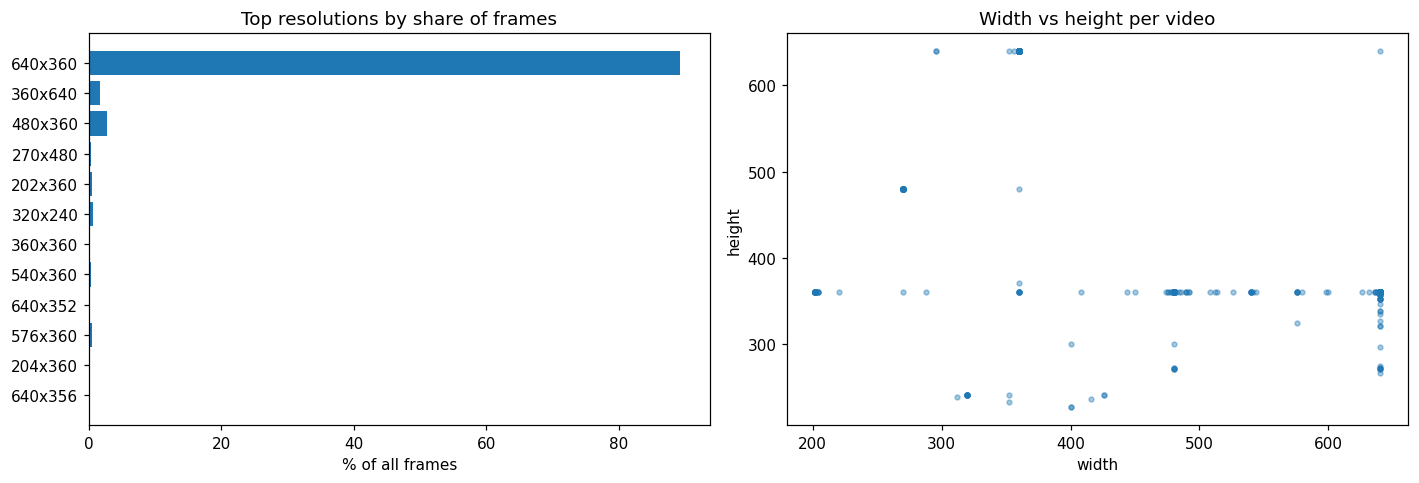

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
top = res_table.head(12)
axes[0].barh(top.index[::-1], top.pct_frames[::-1])
axes[0].set_xlabel("% of all frames"); axes[0].set_title("Top resolutions by share of frames")
axes[1].scatter(ok.width, ok.height, s=10, alpha=0.4)
axes[1].set_xlabel("width"); axes[1].set_ylabel("height"); axes[1].set_title("Width vs height per video")
plt.tight_layout(); plt.show()

### Declared (`json.resolution`) vs actual stream resolution

In [13]:
match = (ok.json_resolution == ok.res)
print(f"json resolution matches stream: {match.mean()*100:.1f}% of videos")
ok.loc[~match, ["video", "json_resolution", "res", "rotation"]].head(15)

json resolution matches stream: 100.0% of videos


,video,json_resolution,res,rotation


### What YOLO actually sees at `imgsz=640`

Ultralytics' default predict letterbox scales the long side to 640 and (for PyTorch, `rect` inference) pads the short side
only up to a multiple of 32. So a 1280x720 frame becomes a 640x384 tensor, not 640x640.
This matters for batching and for TensorRT (which wants fixed shapes): a fixed 640x640 engine pads more and can shift detections slightly.

In [14]:
def yolo_input_shape(w, h, imgsz=640, stride=32):
    r = min(imgsz / h, imgsz / w)
    nw, nh = round(w * r), round(h * r)
    pw = math.ceil(nw / stride) * stride
    ph = math.ceil(nh / stride) * stride
    return f"{pw}x{ph}", r

# rotation of 90/270 swaps width/height after rotating
dw = np.where(ok.rotation.abs() % 180 == 90, ok.height, ok.width)
dh = np.where(ok.rotation.abs() % 180 == 90, ok.width, ok.height)
shapes = [yolo_input_shape(w, h) for w, h in zip(dw, dh)]
ok["yolo_input"] = [s for s, _ in shapes]
ok["downscale"] = [r for _, r in shapes]
print("Model input tensor shapes (W x H), weighted by frames:")
print((ok.groupby("yolo_input").n_frames.sum() / ok.n_frames.sum() * 100).sort_values(ascending=False).round(2))
print(f"\nVideos already <= 640 on the long side (no downscale): {(ok.downscale >= 1).mean()*100:.1f}%")

Model input tensor shapes (W x H), weighted by frames:
yolo_input
640x384    90.82
640x480     3.74
384x640     2.53
640x448     0.64
640x416     0.62
640x512     0.42
640x288     0.41
640x352     0.40
640x640     0.11
640x320     0.09
480x640     0.06
416x640     0.05
512x640     0.03
640x576     0.03
640x544     0.02
320x640     0.02
352x640     0.01
Name: n_frames, dtype: float64

Videos already <= 640 on the long side (no downscale): 100.0%


## 5. Duration, frame rate, total workload

In [15]:
total_hours = ok.last_rel_s.sum() / 3600
total_frames = int(ok.n_frames.sum())
total_seconds = int(ok.n_seconds.sum())
print(f"Total footage: {total_hours:.1f} h | total frames: {total_frames:,} | output lines (seconds): {total_seconds:,}")
print(f"Mean frames per second of footage: {total_frames / ok.last_rel_s.sum():.2f}")
ok[["last_rel_s", "json_duration_s", "container_duration_s", "avg_fps", "n_frames", "n_seconds", "mp4_mb", "bit_rate_kbps"]].describe().round(2)

Total footage: 128.0 h | total frames: 12,981,615 | output lines (seconds): 461,757
Mean frames per second of footage: 28.16


,last_rel_s,json_duration_s,container_duration_s,avg_fps,n_frames,n_seconds,mp4_mb,bit_rate_kbps
count,1650.00,1650.00,1650.00,1650.00,1650.00,1650.00,1650.00,1650.00
mean,279.34,279.44,279.40,28.10,7867.65,279.85,14.43,309.61
std,192.91,192.90,192.91,2.91,5565.76,192.92,11.41,140.95
min,19.15,19.00,19.20,7.00,520.00,20.00,0.63,24.36
25%,108.70,109.00,108.81,25.00,2927.50,109.00,4.92,205.17
50%,242.36,242.50,242.42,29.97,6784.00,242.50,11.63,300.39
75%,439.53,439.75,439.59,30.00,12247.50,440.00,21.55,405.52
max,658.12,658.00,658.17,30.02,19677.00,659.00,57.58,716.60


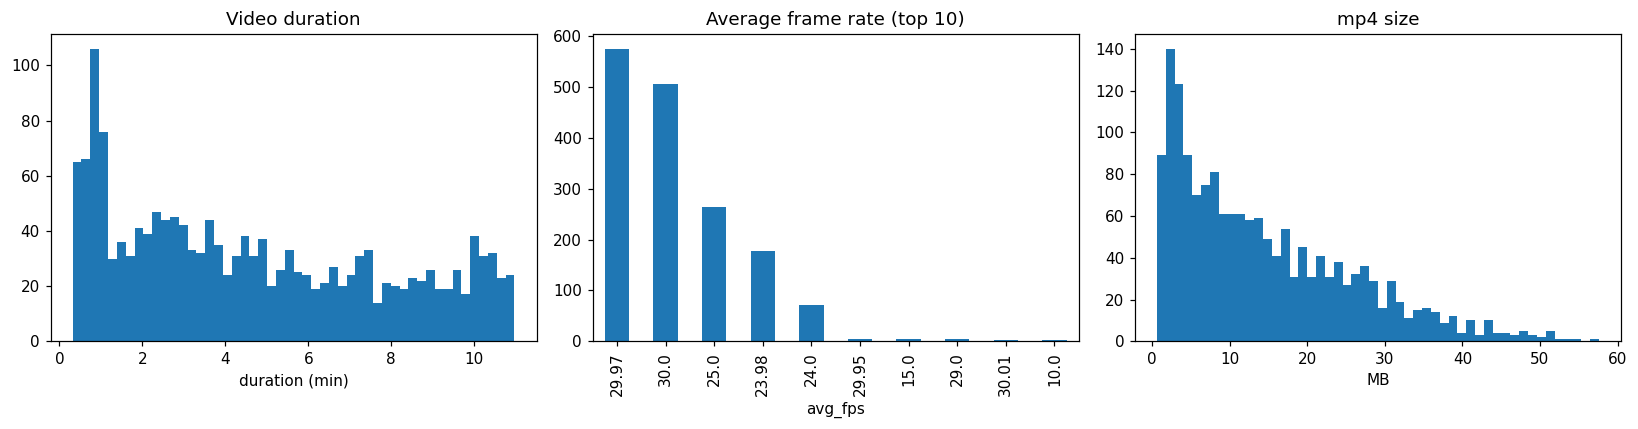

avg_fps
29.97    575
30.00    505
25.00    265
23.98    177
24.00     71
29.95      5
15.00      5
29.00      4
30.01      3
10.00      3
29.76      2
30.02      2
29.94      2
29.92      2
29.78      1
Name: count, dtype: int64


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(ok.last_rel_s / 60, bins=50); axes[0].set_xlabel("duration (min)"); axes[0].set_title("Video duration")
fps_round = ok.avg_fps.round(2)
fps_round.value_counts().head(10).plot.bar(ax=axes[1]); axes[1].set_title("Average frame rate (top 10)")
axes[2].hist(ok.mp4_mb, bins=50); axes[2].set_xlabel("MB"); axes[2].set_title("mp4 size")
plt.tight_layout(); plt.show()
print(fps_round.value_counts().head(15))

In [ ]:
dur_gap = (ok.last_rel_s - ok.json_duration_s)
print("stream duration minus json duration_seconds (s):")
print(dur_gap.describe().round(2))

## 6. Timestamps: VFR, offsets, frames per one-second bucket

The brief defines seconds from **the first decoded frame's timestamp**, using timestamps (not frame index).
So we need to know: do videos start at pts 0? Are frame intervals constant? How many frames land in each second?

In [17]:
print(f"Videos whose first frame pts != 0: {(ok.first_pts_s.abs() > 1e-6).sum()}  (max offset {ok.first_pts_s.abs().max():.3f}s)")
print(f"First *decoded* frame differs from smallest packet pts: {((ok.first_decoded_pts_s - ok.first_pts_s).abs() > 1e-6).sum()}")
vfr = ok.dt_cv > 0.05
print(f"Variable-frame-rate-ish videos (frame-interval CV > 5%): {vfr.sum()}")
print(f"Videos with duplicate pts: {(ok.dup_pts > 0).sum()}; videos with empty 1-s buckets (gaps): {(ok.empty_buckets > 0).sum()}")
ok.loc[vfr, ["video", "avg_fps", "dt_min_ms", "dt_median_ms", "dt_max_ms", "dt_cv", "fpsbucket_min", "fpsbucket_max"]].sort_values("dt_cv", ascending=False).head(10)

Videos whose first frame pts != 0: 0  (max offset 0.000s)
First *decoded* frame differs from smallest packet pts: 0
Variable-frame-rate-ish videos (frame-interval CV > 5%): 0
Videos with duplicate pts: 0; videos with empty 1-s buckets (gaps): 0


,video,avg_fps,dt_min_ms,dt_median_ms,dt_max_ms,dt_cv,fpsbucket_min,fpsbucket_max


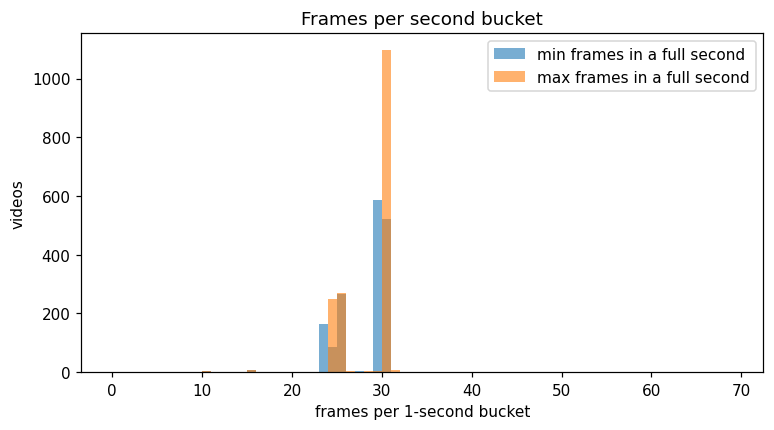

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(ok.fpsbucket_min, bins=range(0, 70), alpha=0.6, label="min frames in a full second")
ax.hist(ok.fpsbucket_max, bins=range(0, 70), alpha=0.6, label="max frames in a full second")
ax.set_xlabel("frames per 1-second bucket"); ax.set_ylabel("videos"); ax.legend(); ax.set_title("Frames per second bucket")
plt.show()

## 7. Codec, GOP and B-frames (decode cost)

In [19]:
print(ok.codec.value_counts(), "\n")
print(ok.profile.value_counts(), "\n")
print(ok.pix_fmt.value_counts(), "\n")
print("has_b_frames:", ok.has_b_frames.value_counts().to_dict())
print("audio streams:", ok.n_audio_streams.value_counts().to_dict())
print("\nGOP (frames between keyframes):")
print(ok.gop_median_frames.describe().round(1))

codec
h264    1650
Name: count, dtype: int64 

profile
Main                    1556
Constrained Baseline      94
Name: count, dtype: int64 

pix_fmt
yuv420p    1650
Name: count, dtype: int64 

has_b_frames: {True: 1376, False: 274}
audio streams: {1: 1650}

GOP (frames between keyframes):
count    1650.0
mean      117.6
std        44.5
min         1.0
25%        76.6
50%       128.0
75%       160.0
max       240.0
Name: gop_median_frames, dtype: float64


## 8. Rotation tags

In [20]:
print(ok.rotation.value_counts())
ok.loc[ok.rotation != 0, ["video", "res", "rotation", "frame_w", "frame_h", "json_resolution"]]

rotation
0    1650
Name: count, dtype: int64


,video,res,rotation,frame_w,frame_h,json_resolution


## 9. Content categories

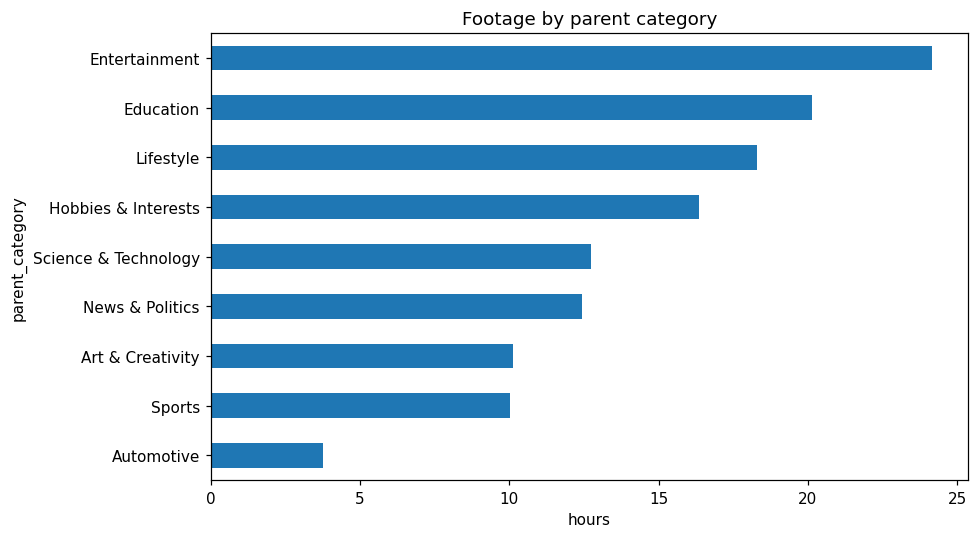

fine_category
Marketing Strategies    46
Stand-up                35
Match Replays           34
Editorials              33
Climate Change          30
Gaming Livestreams      27
Film Trailers           27
Documentary Profiles    26
Expert Interviews       25
Physics                 25
Political Interviews    24
Celebrity Interviews    24
Music Videos            24
Ranked Lists            23
Poetry Readings         22
Short Films             22
AI Concepts             22
Chemistry               22
Motivational Talks      21
Event Livestreams       21
Name: count, dtype: int64

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))
cat_hours = ok.groupby("parent_category").last_rel_s.sum().sort_values() / 3600
cat_hours.plot.barh(ax=ax); ax.set_xlabel("hours"); ax.set_title("Footage by parent category")
plt.tight_layout(); plt.show()
ok.fine_category.value_counts().head(20)

## 10. What the frames look like

One frame from the middle of 16 random videos (rotation applied for display).

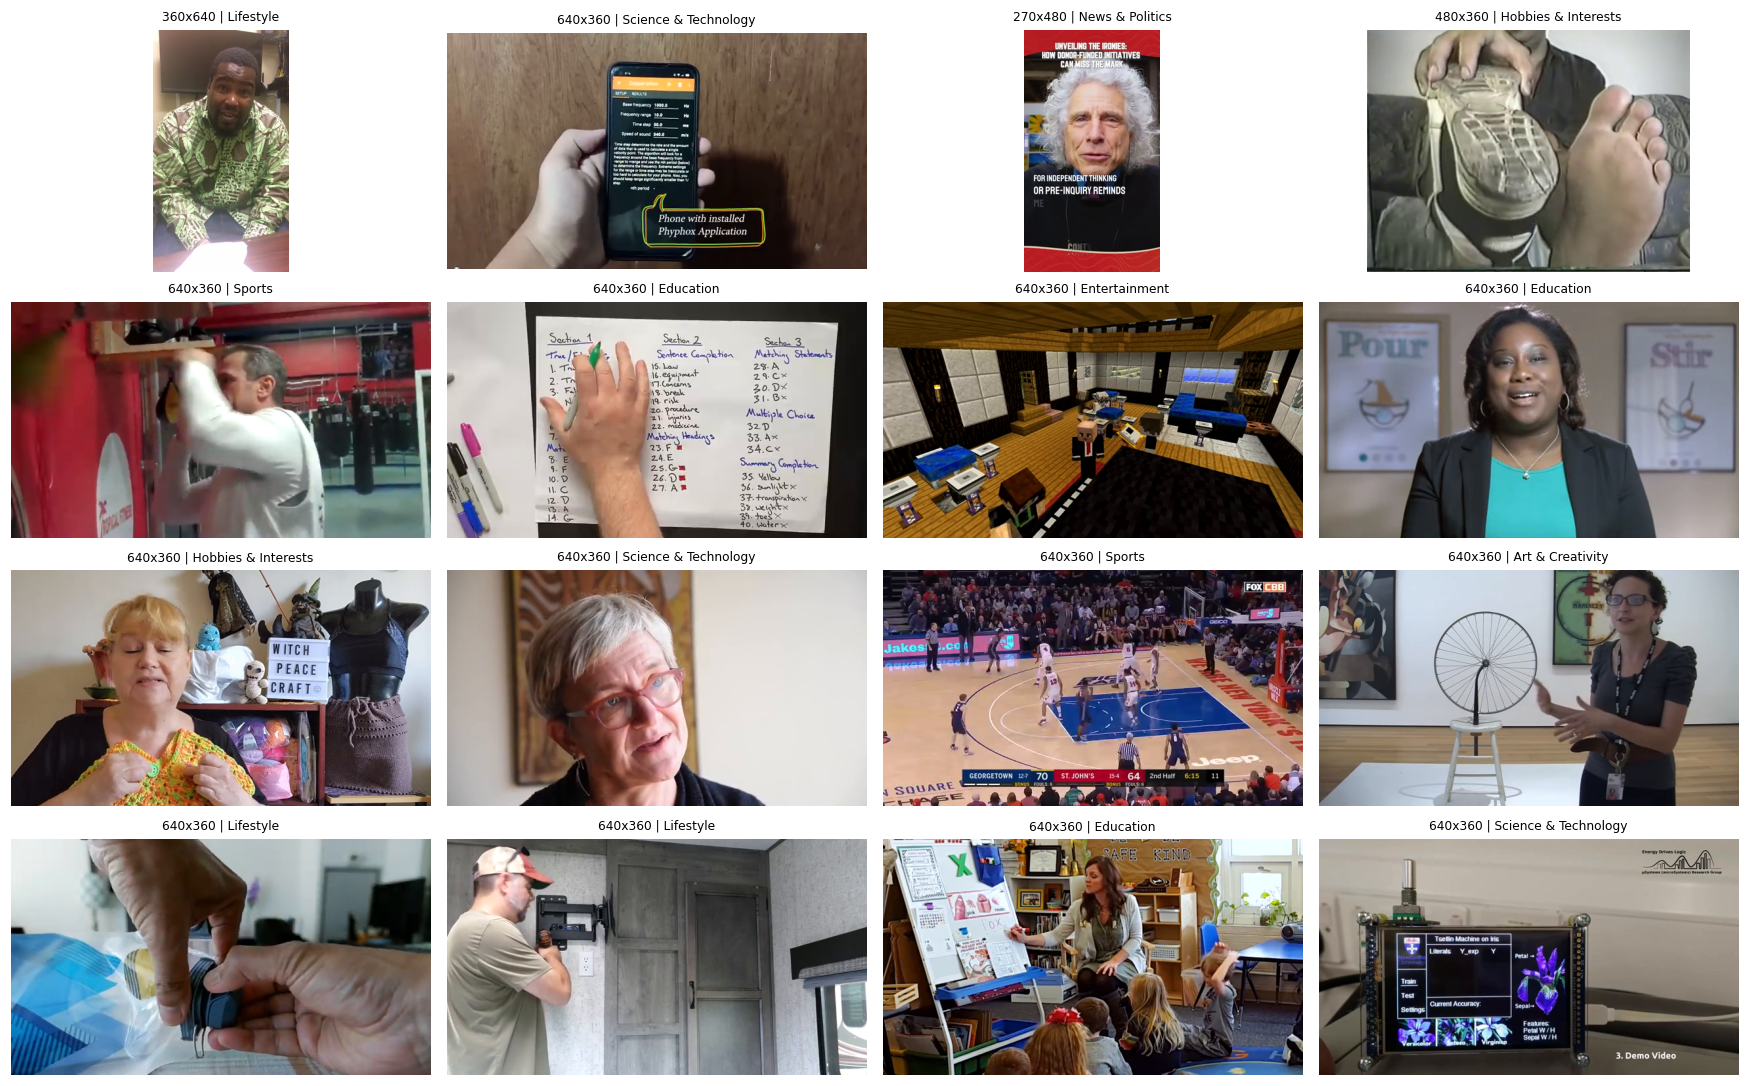

In [22]:
def frame_at(mp4_bytes, t_rel):
    with av.open(io.BytesIO(mp4_bytes)) as c:
        v = c.streams.video[0]
        start = v.start_time or 0
        c.seek(int(start + t_rel / float(v.time_base)), stream=v)
        for fr in c.decode(v):
            if fr.time is None or fr.time >= t_rel + float(start * v.time_base):
                img = fr.to_ndarray(format="rgb24")
                rot = int(getattr(fr, "rotation", 0) or 0)
                if rot:
                    img = np.rot90(img, k=(rot // 90) % 4)
                return img
    return None

random.seed(0)
sample = ok.sample(16, random_state=0)
fig, axes = plt.subplots(4, 4, figsize=(16, 10))
for ax, (_, r) in zip(axes.flat, sample.iterrows()):
    t = pq.read_table(DATA_DIR / r.file, columns=["mp4"]).column("mp4")[int(r.row)].as_py()
    img = frame_at(t, r.last_rel_s / 2)
    if img is not None:
        ax.imshow(img)
    ax.set_title(f"{r.res} | {r.parent_category}"[:45], fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 11. CPU decode speed (this laptop)

Decode is likely the CPU bottleneck in `run.py`. Benchmark the first 300 frames of one video per common resolution:
- plain decode (frame objects only),
- decode + conversion to a BGR numpy array (what YOLO needs),
- decode with FFmpeg frame threading,
- decode with `skip_frame="NONREF"` (decoder drops non-reference frames — fewer frames, cheaper).

In [23]:
def bench(mp4_bytes, n=300, to_bgr=False, threads=False, skip=None):
    with av.open(io.BytesIO(mp4_bytes)) as c:
        v = c.streams.video[0]
        if threads:
            v.thread_type = "AUTO"
        if skip:
            v.codec_context.skip_frame = skip
        t0 = time.perf_counter(); k = 0
        for fr in c.decode(v):
            if to_bgr:
                fr.to_ndarray(format="bgr24")
            k += 1
            if k >= n:
                break
        return k, k / (time.perf_counter() - t0)

bench_rows = []
for res in res_table.index[:4]:
    r = ok[ok.res == res].iloc[0]
    b = pq.read_table(DATA_DIR / r.file, columns=["mp4"]).column("mp4")[int(r.row)].as_py()
    for name, kw in [("decode", {}), ("decode+bgr", {"to_bgr": True}),
                     ("decode+bgr, threads", {"to_bgr": True, "threads": True}),
                     ("decode NONREF", {"skip": "NONREF"})]:
        try:
            k, fps = bench(b, **kw)
        except Exception as e:
            k, fps = 0, np.nan
        bench_rows.append({"res": res, "codec": r.codec, "mode": name, "frames": k, "fps": round(fps, 1)})
bench_df = pd.DataFrame(bench_rows)
bench_df.pivot(index="res", columns="mode", values="fps")

mode,decode,decode NONREF,decode+bgr,"decode+bgr, threads"
res,,,,
270x480,7330.9,6538.4,426.1,402.2
360x640,1928.7,1204.5,190.8,230.9
480x360,1738.5,1829.8,277.7,447.7
640x360,2332.7,1216.4,273.0,319.9


## 12. Summary numbers for planning

In [24]:
summary = {
    "videos": len(df),
    "probe failures": int(df.error.notna().sum()),
    "hours of footage": round(total_hours, 1),
    "total frames": total_frames,
    "output lines (video-seconds)": total_seconds,
    "most common resolution": res_table.index[0],
    "share of frames at most common res (%)": round(res_table.pct_frames.iloc[0], 1),
    "median fps": round(ok.avg_fps.median(), 2),
    "videos with rotation tag": int((ok.rotation != 0).sum()),
    "VFR-ish videos": int(vfr.sum()),
    "codecs": ok.codec.value_counts().to_dict(),
    "frames if sampling 1 / 2 / 5 per second": [total_seconds * k for k in (1, 2, 5)],
}
pd.Series(summary)

videos                                                          1650
probe failures                                                     0
hours of footage                                               128.0
total frames                                                12981615
output lines (video-seconds)                                  461757
most common resolution                                       640x360
share of frames at most common res (%)                          89.3
median fps                                                     29.97
videos with rotation tag                                           0
VFR-ish videos                                                     0
codecs                                                {'h264': 1650}
frames if sampling 1 / 2 / 5 per second    [461757, 923514, 2308785]
dtype: object